In [3]:
import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
from cmocean import plots, cm
from adjustText import adjust_text
from pathlib import Path

In [4]:
ROOT = Path.cwd().parent
DATA = ROOT    / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

In [6]:
world_map = gpd.read_file(DATA / 'simplified-world-map/world-map.shp')
world_map = world_map.drop([31])
China_province_map = gpd.read_file(DATA / 'China-map/省.shp')
hk_row = China_province_map[China_province_map['省'] == '香港特别行政区'].copy()
mo_row = China_province_map[China_province_map['省'] == '澳门特别行政区'].copy()
hk_row = hk_row.assign(GID_0="HKG", COUNTRY="Hong Kong")[["GID_0", "COUNTRY", "geometry"]]
mo_row = mo_row.assign(GID_0="MAC", COUNTRY="Macau")[["GID_0", "COUNTRY", "geometry"]]
world_map = pd.concat([world_map, hk_row, mo_row], ignore_index=True)
world_map_eck4 = world_map.to_crs('ESRI:54012')

In [7]:
production_142 = pd.read_csv(DATA / 'production-142.csv', index_col=0)
economies_142 = production_142.columns.tolist()
mapping = pd.read_excel(DATA / 'contents.xlsx', sheet_name='merged_countries')  # parent, child, child_name
child_to_parent = dict(zip(mapping["child"], mapping["parent"]))

In [8]:
world_map_eck4["economies_142"] = world_map_eck4["GID_0"].map(child_to_parent)
# 3. 对于本身就在 economies_142 的现代国家，保持自己
world_map_eck4.loc[
    world_map_eck4["GID_0"].isin(economies_142),
    "economies_142"
] = world_map_eck4["GID_0"]

In [9]:
print(world_map_eck4[["GID_0", "COUNTRY", "economies_142"]].head())

  GID_0                           COUNTRY economies_142
0   IRN                              Iran           IRN
1   BLM                  Saint-Barthélemy           NaN
2   UGA                            Uganda           UGA
3   SLE                      Sierra Leone           SLE
4   VCT  Saint Vincent and the Grenadines           NaN


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


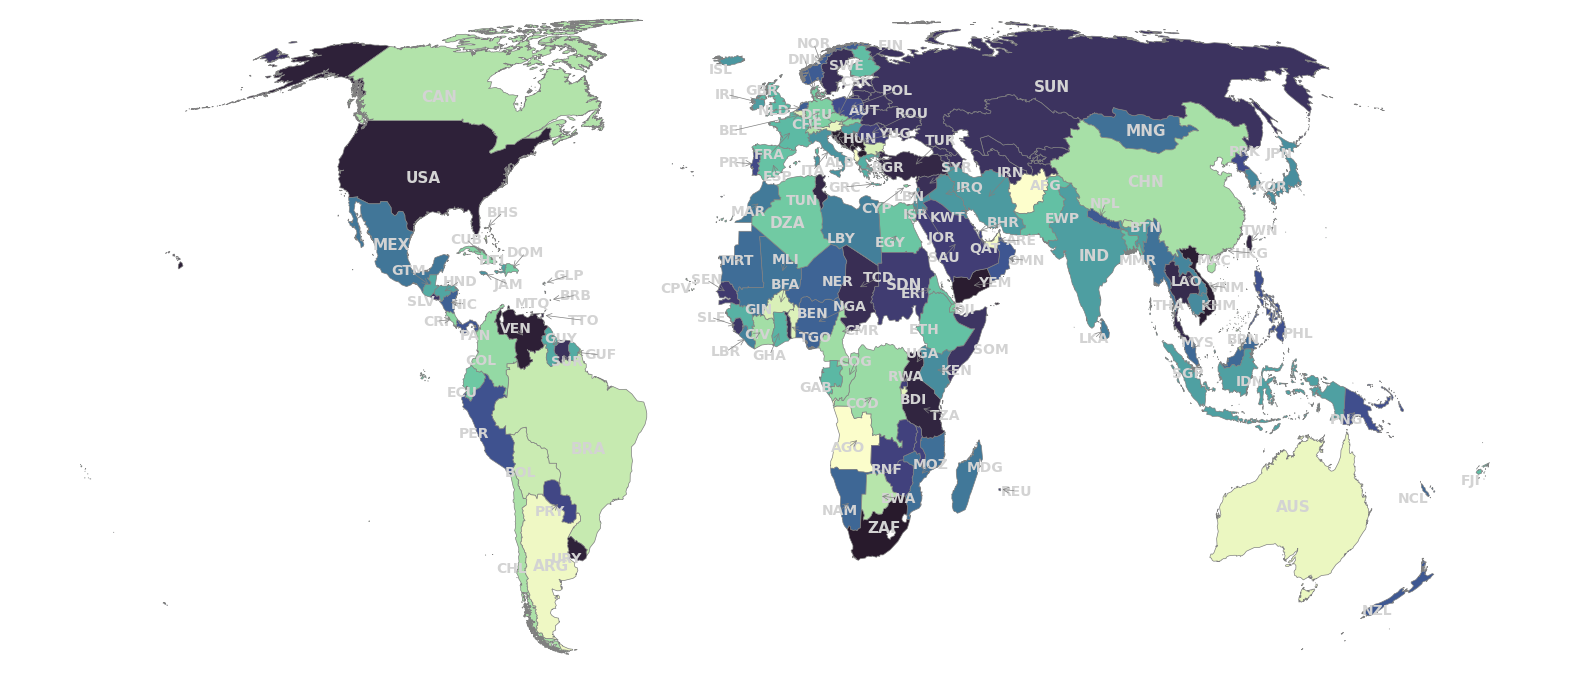

In [10]:
fig, ax = plt.subplots(figsize=(20, 12))

# 1. 按 economies_142 着色
world_map_eck4.plot(
    column="economies_142",
    ax=ax,
    legend=False,
    cmap=cm.deep,
    edgecolor="grey",
    linewidth=0.5
)

# 2. 标注逻辑
highlight = world_map_eck4[world_map_eck4["economies_142"].notna()]
font_color = "lightgrey"
font_size = 11
# 1. 定义大国名单（可扩展）
big_economies = ["ARG", "USA", "CHN", "BRA", "CAN", "AUS", "DZA", "RUS", "IND", "MNG", "MEX", "SDN", "ZAF"]
representative = {
    "SUN": "RUS",
    "YUG": "SRB",   # 或者 "BIH" / "HRV" 等，根据你需求修改
    "CSK": "CZE",
    "RNF": "ZWE",
    "EWP": "PAK",
    "BEL": "BEL"
}
texts = []

for idx, row in world_map_eck4.iterrows():
    econ = row["economies_142"]
    gid = row["GID_0"]
    if pd.isna(econ):
        continue

    # ---- 合并国家逻辑 ----
    if econ in representative:
        if gid != representative[econ]:
            continue  # 跳过非代表国

    point = row.geometry.representative_point()

    # ---- 大国逻辑 ----
    if econ in big_economies:
        ax.text(point.x, point.y, econ,
                fontsize=font_size, ha="center", va="center",
                color=font_color, fontweight="bold")
    
    elif econ == "SUN":
        # 只取俄罗斯的几何
        rus = world_map_eck4[world_map_eck4["GID_0"] == "RUS"].iloc[0]
        point = rus.geometry.representative_point()
        ax.text(point.x, point.y, "SUN",
                fontsize=font_size, ha="center", color=font_color, fontweight="bold")

    else:
        # 小国 → 收集后用 adjust_text
        texts.append(
            ax.text(point.x, point.y, econ,
                    fontsize=font_size-1, ha="center", va="center",
                    color=font_color, fontweight="bold")
        )

# 3. 用 adjust_text 调整小国标签
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="->", color="grey", lw=0.5),
    expand_points=(2.0, 2.0),
    expand_text=(1.2, 1.2),
    force_text=(0.5, 0.5)
)
# 4. 美化
# ax.set_title("142 Economies (colored by economies_142)", fontsize=16)
ax.set_axis_off()
ax.set_ylim(-7.2e6, 8.6e6)

plt.show()
fig.savefig(FIGURES / 'supplementary-Figure-1.jpg', dpi=600, bbox_inches='tight')